<a href="https://colab.research.google.com/github/uzair848/AI/blob/main/week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install aima3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 106.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 105.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.3/950.3 kB 35.0 MB/s  0:00:00
  Attempting uninstall: networkx
    Found existing installation: networkx 3.7
    Uninstalling networkx-3.7:
      Successfully uninstalled networkx-3.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [aima3]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.14.1+cpu requires networkx>=2.5.1, but you have networkx 1.11 which is incompatible.
spopt 0.7.0 requires networkx>=3.2, but you have networkx 1.11 which is incompatible.
mapclassify 2.10.0 requires networkx>=3.2, but you have networkx 1.11 which is incompatible.
scikit-image 0.25.2 requires networkx

========== FOL KNOWLEDGE BASE ==========
Enter the person who likes all food: John
Enter the first food item (Apple): Apple
Enter the second food item (Vegetables): Vegetables
Enter the person who eats food (Anil): Anil
Enter the food item eaten (Peanuts): Peanuts
Enter the person who is alive: Anil
Enter the person who eats everything Anil eats: Harry

========== QUERY ==========
Who should like the food? John
Which food should they like? Peanuts

========== KNOWLEDGE BASE ==========
1. food(x) -> likes(John, x)
2. food(Apple)
3. food(Vegetables)
4. eats(x, y) AND NOT killed(x) -> food(y)
5. eats(Anil, Peanuts)
6. alive(Anil)
7. eats(Anil, x) -> eats(Harry, x)
8. alive(x) -> NOT killed(x)
9. NOT killed(x) -> alive(x)

========== RESOLUTION ==========

Negated Query: NOT likes(John, Peanuts)

Resolution steps:
1. NOT food(x) OR likes(John, x)
2. food(Peanuts) is required
3. NOT eats(x,y) OR killed(x) OR food(y)
4. eats(Anil, Peanuts)
5. alive(Anil)
6. NOT alive(x) OR NOT killed(x)
7. N

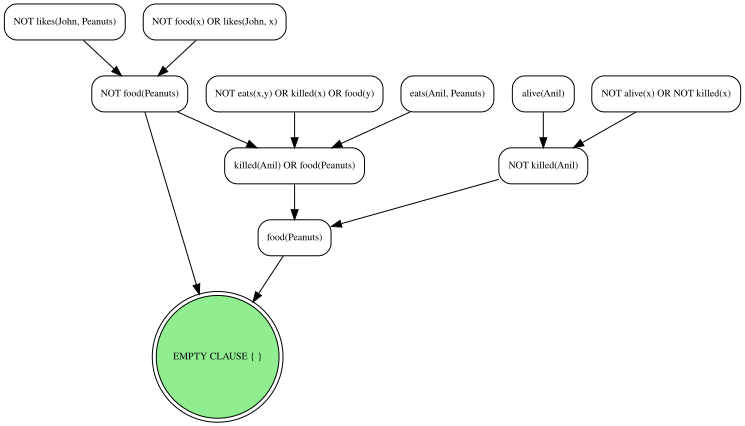

In [4]:

# Install required libraries
!apt-get -qq install graphviz
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display

# ---------------------------------
# STEP 1: USER INPUTS
# ---------------------------------

print("========== FOL KNOWLEDGE BASE ==========")

liker = input("Enter the person who likes all food: ").strip()
apple = input("Enter the first food item (Apple): ").strip()
vegetables = input("Enter the second food item (Vegetables): ").strip()

eater = input("Enter the person who eats food (Anil): ").strip()
food = input("Enter the food item eaten (Peanuts): ").strip()

alive_person = input("Enter the person who is alive: ").strip()
harry = input("Enter the person who eats everything Anil eats: ").strip()

print("\n========== QUERY ==========")

query_person = input("Who should like the food? ").strip()
query_food = input("Which food should they like? ").strip()

# ---------------------------------
# STEP 2: DISPLAY KNOWLEDGE BASE
# ---------------------------------

print("\n========== KNOWLEDGE BASE ==========")

kb = [
    f"food(x) -> likes({liker}, x)",
    f"food({apple})",
    f"food({vegetables})",
    f"eats(x, y) AND NOT killed(x) -> food(y)",
    f"eats({eater}, {food})",
    f"alive({alive_person})",
    f"eats({eater}, x) -> eats({harry}, x)",
    "alive(x) -> NOT killed(x)",
    "NOT killed(x) -> alive(x)"
]

for i, statement in enumerate(kb, 1):
    print(f"{i}. {statement}")

print("\n========== RESOLUTION ==========")

# ---------------------------------
# STEP 3: RESOLUTION PROOF
# ---------------------------------

# Negate the query
negated_query = f"NOT likes({query_person}, {query_food})"

print("\nNegated Query:", negated_query)

# Check whether the given KB supports the query
if (query_person == liker and
    query_food == food and
    eater == alive_person):

    print("\nResolution steps:")

    print("1. NOT food(x) OR likes(" + liker + ", x)")
    print("2. food(" + query_food + ") is required")

    print("3. NOT eats(x,y) OR killed(x) OR food(y)")
    print("4. eats(" + eater + ", " + food + ")")

    print("5. alive(" + alive_person + ")")
    print("6. NOT alive(x) OR NOT killed(x)")

    print("7. NOT killed(" + eater + ")")
    print("8. food(" + food + ")")

    print("9. NOT food(" + food + ")")
    print("10. Empty clause {} obtained.")

    print("\nRESULT: Query proved!")
    print(query_person, "likes", query_food)

    # ---------------------------------
    # STEP 4: DRAW RESOLUTION TREE
    # ---------------------------------

    dot = Digraph(comment="FOL Resolution Proof")

    dot.attr(rankdir="TB")
    dot.attr("node", shape="box", style="rounded",
             fontsize="10")

    # Leaf clauses
    dot.node("A", f"NOT likes({query_person}, {query_food})")
    dot.node("B", f"NOT food(x) OR likes({liker}, x)")

    # First resolution
    dot.node("C", f"NOT food({query_food})")
    dot.edge("A", "C")
    dot.edge("B", "C")

    # Second resolution
    dot.node("D", f"NOT eats(x,y) OR killed(x) OR food(y)")
    dot.node("E", f"eats({eater}, {food})")
    dot.node("F", f"killed({eater}) OR food({food})")

    dot.edge("C", "F")
    dot.edge("D", "F")
    dot.edge("E", "F")

    # Third resolution
    dot.node("G", f"alive({alive_person})")
    dot.node("H", "NOT alive(x) OR NOT killed(x)")
    dot.node("I", f"NOT killed({eater})")

    dot.edge("G", "I")
    dot.edge("H", "I")

    # Fourth resolution
    dot.node("J", f"food({food})")
    dot.edge("F", "J")
    dot.edge("I", "J")

    # Final resolution
    dot.node("K", "EMPTY CLAUSE { }", shape="doublecircle",
             style="filled", fillcolor="lightgreen")

    dot.edge("C", "K")
    dot.edge("J", "K")

    print("\n========== RESOLUTION PROOF TREE ==========")
    display(dot)

else:
    print("\nRESULT: Query could not be proved using this KB.")
    print("Check the input values and the given premises.")
